## Heartbeat-classifier
Heartbeat classifier from MIT-BIH Arrythmia Database

In [15]:
from IPython.display import display
import wfdb
import numpy as np


#### Dataset : MIT-BIH 
- 48 recordings of 30min -> each having 2 ECG signals
- 47 subjects (records 201, 202 from same subject)
- 23 normal recordings (100's files)
- 25 abnormal recordings (200's files)
- for each records, 3 files : signal file (.dat), header file (.hea), annotation file (.art) 


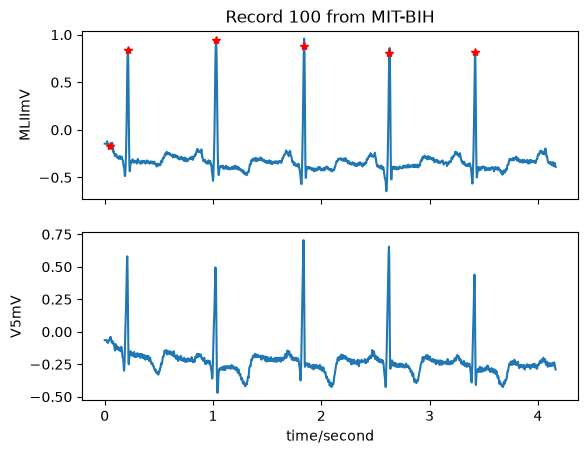

{'record_name': '100',
 'n_sig': 2,
 'fs': 360,
 'counter_freq': None,
 'base_counter': None,
 'sig_len': 1500,
 'base_time': None,
 'base_date': None,
 'comments': ['69 M 1085 1629 x1', 'Aldomet, Inderal'],
 'sig_name': ['MLII', 'V5'],
 'p_signal': array([[-0.145, -0.065],
        [-0.145, -0.065],
        [-0.145, -0.065],
        ...,
        [-0.355, -0.27 ],
        [-0.38 , -0.285],
        [-0.39 , -0.29 ]], shape=(1500, 2)),
 'd_signal': None,
 'e_p_signal': None,
 'e_d_signal': None,
 'file_name': ['100.dat', '100.dat'],
 'fmt': ['212', '212'],
 'samps_per_frame': [1, 1],
 'skew': [None, None],
 'byte_offset': [None, None],
 'adc_gain': [200.0, 200.0],
 'baseline': [1024, 1024],
 'units': ['mV', 'mV'],
 'adc_res': [11, 11],
 'adc_zero': [1024, 1024],
 'init_value': [995, 1011],
 'checksum': [64184, 26661],
 'block_size': [0, 0]}

{'record_name': '100',
 'extension': 'atr',
 'sample': array([  18,   77,  370,  662,  946, 1231]),
 'symbol': ['+', 'N', 'N', 'N', 'N', 'N'],
 'subtype': array([0, 0, 0, 0, 0, 0]),
 'chan': array([0, 0, 0, 0, 0, 0]),
 'num': array([0, 0, 0, 0, 0, 0]),
 'aux_note': ['(N\x00', '', '', '', '', ''],
 'fs': 360,
 'label_store': None,
 'description': None,
 'custom_labels': None,
 'contained_labels': None,
 'ann_len': 6}

In [ ]:
record = wfdb.rdrecord('../../mitbih/100', sampto=1500)
ann = wfdb.rdann('../../mitbih/100', 'atr', sampto=1500)

wfdb.plot_wfdb(record=record, annotation=ann, title="Record 100 from MIT-BIH", time_units='seconds')
display(record.__dict__)
display(ann.__dict__)

## First classification type : detection of abnormal beat
The idea is to cut each signal into windows centered around each beat's peak and use 1D-CNN that slides along the signal to detect abnormal heatbeat. The annotations are used to label each window.

##### Preprocessing : 

In [12]:
# Separating patients in 2 sets (training, test sets), as in Chazal et al. 2004
training_patients = ['101', '106', '108', '109', '112', '114', '115', '116', '118', '119', '122', '124', '201', '203', '205', '207', '208', '209', '215', '220', '223', '230']
testing_patients = ['100', '103', '105', '111', '113', '117', '121', '123', '200', '202', '210', '212', '213', '214', '219', '221', '222', '228', '231', '232', '233', '234']

In [30]:
# Equivalence between MIT-BIH beat types and standard AAMI
# Link : https://www.researchgate.net/figure/Mapping-between-MIT-BIH-and-AAMI-labels_tbl1_348757037
 
dic = {'N' : ['N', '.', 'L', 'R', 'e', 'j'],
       'S' : ['A', 'a', 'J', 'S'],
       'V' : ['V', 'E'],
       'F' : ['F']
       }

dic = {'N' : 'N', '.' : 'N', 'L' : 'N', 'R' : 'N', 'e' : 'N', 'j' : 'N',
       'A' : 'S', 'a' : 'S', 'J' : 'S', 'S' : 'S',
       'V' : 'V', 'E' : 'V',
       'F' : 'F'}

class_idx = {'N' : 0, 'S' : 1, 'V' : 2, 'F' : 3} 

In [40]:
# Function to extract beats and label for one record
def extract_beats(record_nb, before=90, after=110):
    record_name = '../../mitbih/' + record_nb
    rec = wfdb.rdrecord(record_name)
    ann = wfdb.rdann(record_name, 'atr') #ann.sample has the beat peak indexes, ann.symbol has the corresponding MIT-BIH beat type
    channel = np.where(np.array(record.sig_name) == "MLII")
    sig = record.p_signal[:, channel[0]]

    beats, types = [],[]
    for peak, symbol in zip(ann.sample, ann.symbol):
        if symbol not in dic :
            continue
        if peak - before < 0 or peak + after > len(sig) : 
            continue
        beat = sig[peak-before : peak+after]
        type = class_idx[dic[symbol]]
        beats.append(beat)
        types.append(type)

    return np.array(beats), np.array(types)
    

beats, types = extract_beats('100')
print(beats.shape) #(Nb of relevant beats x length of the window (with default, supposed to be 200) x 1 ) -> each window around a relevant beat is a 1d array, and you have as many of them as relevant beat

(4, 200, 1)


In [43]:
# Creating the datasets
def build_datasets(record_nbs): 
    X, y = [],[]
    for record_nb in record_nbs : 
        beats, types = extract_beats(record_nb)
        X.append(beats)
        y.append(types)
    return np.concatenate(X), np.concatenate(y)

X_train, y_train = build_datasets(training_patients)
X_test, y_test = build_datasets(testing_patients)

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)


(101, 200, 1) (101,)
(97, 200, 1) (97,)


##### Training

## Second classification type : detection of abnormal sequence
The idea is to use a 1D-CNN that will slide on each signal to detect if the signal is from a person with normal condition or not. 